# Measure waves, then build interference

This notebook connects the **Waves and interference** lesson to small calculations you can inspect. First measure a water-wave model in centimetres, metres, and seconds. Then use dimensionless quantum amplitudes to build the same 16-bin probability screen as the website.

The water model is an ideal sinusoid, not a fluid simulation. The quantum screen is a normalized teaching model, not a calculation of physical slit diffraction or a particle trajectory.

Read one section at a time. Predict the result before reading its saved output. To experiment, download this notebook and run its cells from top to bottom in a Python environment with NumPy and Matplotlib.

## 1. Prepare a reproducible workspace

NumPy handles the numbers; Matplotlib draws their plots. An explicit random seed makes the detection examples repeatable. These imports and plotting settings do not contain a physical model yet.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update(
    {
        "figure.figsize": (8.4, 3.8),
        "figure.dpi": 120,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": "#24354b",
        "text.color": "#24354b",
        "xtick.color": "#44556c",
        "ytick.color": "#44556c",
        "font.size": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.16,
        "grid.color": "#718198",
        "lines.linewidth": 2.4,
        "savefig.bbox": "tight",
    }
)
BLUE, GREEN, AMBER = "#3c6db3", "#27836d", "#b87920"
rng = np.random.default_rng(20261013)
print(f"Ready: NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("All plots below come from the code in this notebook.")

Ready: NumPy 2.5.4, Matplotlib 3.11.2
All plots below come from the code in this notebook.


## 2. Separate a travelling pattern from a moving cork

Use a wave with amplitude **2 cm**, wavelength **4 m**, and frequency **1 Hz**. The formula is `y(x, t) = A * sin(2π * (x / wavelength - frequency * t))`.

The left plot shows two snapshots of the pattern along the water. The right plot watches one fixed location, `x = 1 m`, over time. Compare the cork's horizontal position in the two snapshots: the pattern travels while this idealized cork stays at the same horizontal location and changes height.

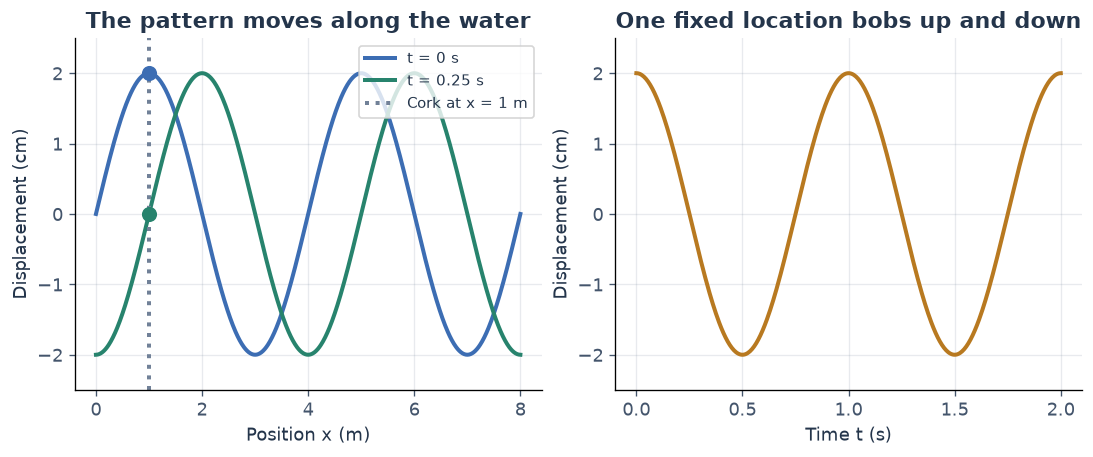

The cork is at x = 1 m in both snapshots: height changes from +2 cm to 0 cm.
Wave speed = wavelength × frequency = 4 m/s in this ideal travelling-wave model.


In [2]:
amplitude_cm, wavelength_m, frequency_hz = 2.0, 4.0, 1.0


def displacement(x_m, t_s):
    return amplitude_cm * np.sin(2 * np.pi * (x_m / wavelength_m - frequency_hz * t_s))


x = np.linspace(0, 8, 801)
t = np.linspace(0, 2, 401)
cork_x = 1.0
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.7), layout="constrained")
for time, color in [(0.0, BLUE), (0.25, GREEN)]:
    axes[0].plot(x, displacement(x, time), color=color, label=f"t = {time:g} s")
    axes[0].scatter([cork_x], [displacement(cork_x, time)], color=color, s=65, zorder=3)
axes[0].axvline(cork_x, color="#718198", linestyle=":", label="Cork at x = 1 m")
axes[0].set(
    title="The pattern moves along the water",
    xlabel="Position x (m)",
    ylabel="Displacement (cm)",
    ylim=(-2.5, 2.5),
)
axes[0].legend(fontsize=9, loc="upper right")
axes[1].plot(t, displacement(cork_x, t), color=AMBER)
axes[1].set(
    title="One fixed location bobs up and down",
    xlabel="Time t (s)",
    ylabel="Displacement (cm)",
    ylim=(-2.5, 2.5),
)
axes[1].set_xticks([0, 0.5, 1, 1.5, 2])
plt.show()
assert np.isclose(displacement(1.0, 0.0), 2.0)
assert np.isclose(displacement(1.0, 0.25), 0.0)
print("The cork is at x = 1 m in both snapshots: height changes from +2 cm to 0 cm.")
print(
    "Wave speed = wavelength × frequency = 4 m/s in this ideal travelling-wave model."
)

## 3. Measure three different features

**Amplitude** is the greatest distance from zero displacement. **Wavelength** is the distance between neighbouring crests in a position snapshot. **Frequency** is the number of cycles each second at one position.

Keep the units attached to the values. A crest at `+2 cm` and a trough at `-2 cm` give amplitude `2 cm`, not `4 cm`. Two cycles in two seconds give `1 Hz`. Predict the printed measurements before running the cell.

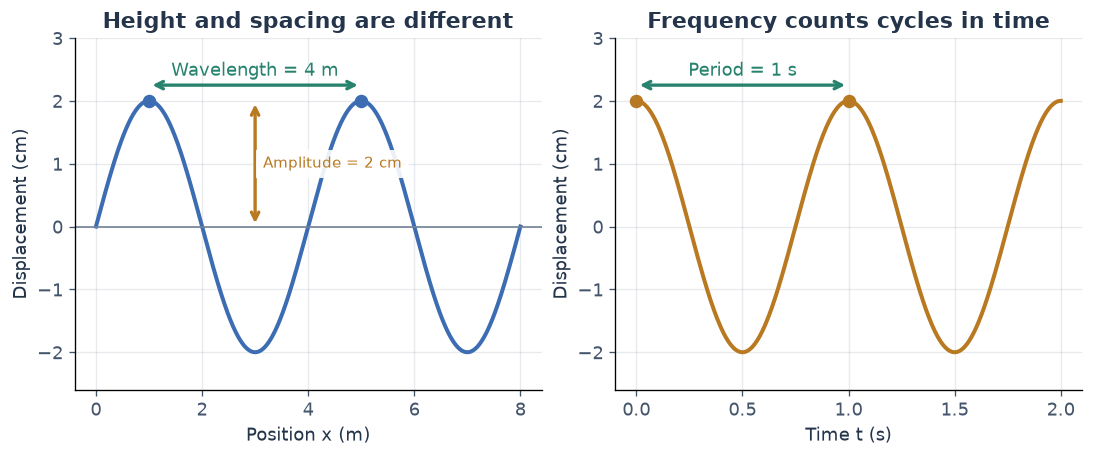

Amplitude: 2.0 cm
Wavelength: 4.0 m
Period: 1.0 s; frequency: 1.0 cycles/s = 1.0 Hz


In [3]:
period_s = 1 / frequency_hz
crest_positions_m = np.array([wavelength_m / 4, wavelength_m / 4 + wavelength_m])
crest_times_s = np.array([0.0, period_s])
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.7), layout="constrained")
axes[0].plot(x, displacement(x, 0), color=BLUE)
axes[0].axhline(0, color="#718198", linewidth=1)
axes[0].annotate(
    "",
    xy=(3, amplitude_cm),
    xytext=(3, 0),
    arrowprops={"arrowstyle": "<->", "color": AMBER, "lw": 2},
)
axes[0].text(
    3.15,
    1.0,
    "Amplitude = 2 cm",
    color=AMBER,
    va="center",
    fontsize=9,
    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
)
axes[0].annotate(
    "",
    xy=(crest_positions_m[1], 2.25),
    xytext=(crest_positions_m[0], 2.25),
    arrowprops={"arrowstyle": "<->", "color": GREEN, "lw": 2},
)
axes[0].text(3, 2.4, "Wavelength = 4 m", color=GREEN, ha="center")
axes[0].scatter(crest_positions_m, [2, 2], color=BLUE, s=50)
axes[0].set(
    xlabel="Position x (m)",
    ylabel="Displacement (cm)",
    ylim=(-2.6, 3.0),
    title="Height and spacing are different",
)
axes[1].plot(t, displacement(cork_x, t), color=AMBER)
axes[1].scatter(crest_times_s, [2, 2], color=AMBER, s=50)
axes[1].annotate(
    "",
    xy=(1, 2.25),
    xytext=(0, 2.25),
    arrowprops={"arrowstyle": "<->", "color": GREEN, "lw": 2},
)
axes[1].text(0.5, 2.4, "Period = 1 s", ha="center", color=GREEN)
axes[1].set(
    xlabel="Time t (s)",
    ylabel="Displacement (cm)",
    ylim=(-2.6, 3.0),
    title="Frequency counts cycles in time",
)
plt.show()
print(f"Amplitude: {np.max(np.abs(displacement(x, 0))):.1f} cm")
print(f"Wavelength: {np.diff(crest_positions_m)[0]:.1f} m")
print(
    f"Period: {period_s:.1f} s; frequency: {frequency_hz:.1f} cycles/s = "
    f"{frequency_hz:.1f} Hz"
)
assert np.isclose(np.diff(crest_positions_m)[0], wavelength_m)
assert np.isclose(period_s * frequency_hz, 1.0)

## 4. Add displacements before drawing the result

Now use two waves with amplitude **1 cm** each and the same wavelength. Shift wave B by a relative phase. At each position, their total water displacement is `y_A + y_B`.

At the marked position `x = 1 m`, wave A contributes `+1 cm`. Predict wave B and the total for relative phases `0°`, `90°`, and `180°`. These curves show water displacement, not quantum probability or the wave's total energy.

  0° at x = 1 m: A = +1 cm, B = +1 cm, total = 2 cm
 90° at x = 1 m: A = +1 cm, B = +0 cm, total = 1 cm
180° at x = 1 m: A = +1 cm, B = -1 cm, total = 0 cm


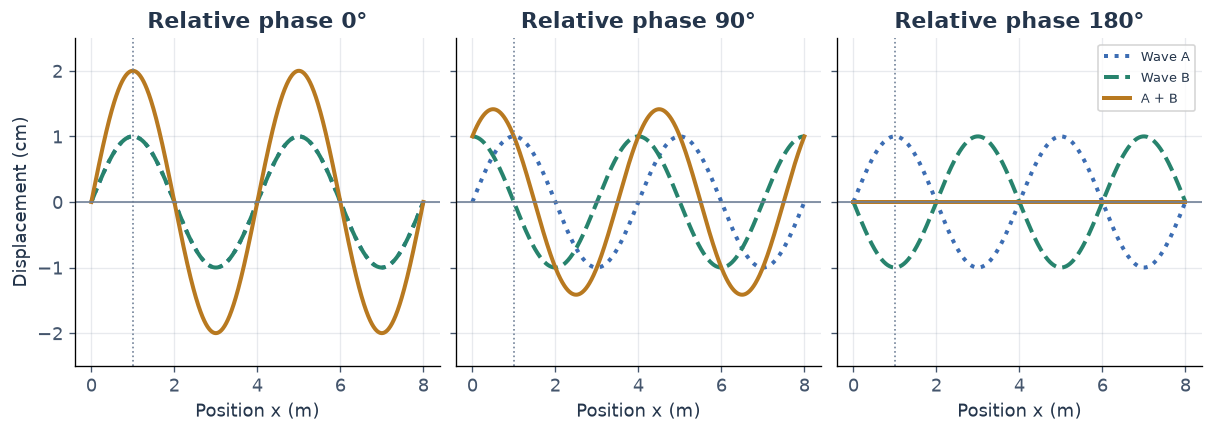

Opposite equal displacements cancel. This does not assert that energy disappeared.


In [4]:
wave_a = np.sin(2 * np.pi * x / 4)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained", sharey=True)
for ax, phase_deg in zip(axes, [0, 90, 180]):
    phase_rad = np.deg2rad(phase_deg)
    wave_b = np.sin(2 * np.pi * x / 4 + phase_rad)
    total = wave_a + wave_b
    ax.plot(x, wave_a, color=BLUE, linestyle=":", label="Wave A")
    ax.plot(x, wave_b, color=GREEN, linestyle="--", label="Wave B")
    ax.plot(x, total, color=AMBER, label="A + B")
    ax.axvline(1, color="#718198", linestyle=":", linewidth=1)
    ax.axhline(0, color="#718198", linewidth=1)
    ax.set(
        title=f"Relative phase {phase_deg}°", xlabel="Position x (m)", ylim=(-2.5, 2.5)
    )
    at_marker_b = np.sin(np.pi / 2 + phase_rad)
    print(
        f"{phase_deg:3d}° at x = 1 m: A = +1 cm, B = {at_marker_b:+.0f} cm, total = "
        f"{1 + at_marker_b:.0f} cm"
    )
axes[0].set_ylabel("Displacement (cm)")
axes[2].legend(loc="upper right", fontsize=8)
plt.show()
assert np.allclose(wave_a + np.sin(2 * np.pi * x / 4 + np.pi), 0, atol=1e-12)
print(
    "Opposite equal displacements cancel. This does not assert that energy disappeared."
)

## 5. Build the lesson's normalized quantum screen

Water height helped us understand addition. A **quantum amplitude** has a different meaning: it predicts a detection probability after we take its squared magnitude.

Our screen has 16 outcome bins. For bin index `j`, route A contributes `m` and route B contributes `m * exp(i * (phase + 2πj/16))`, where `m = 1/sqrt(32)`. Python writes the imaginary unit as `1j`.

Without a path record, use `abs(a + b)**2`. With a perfect path record, the routes are distinguishable and use `abs(a)**2 + abs(b)**2`. This ideal model has two orthogonal path modes, so both complete distributions sum to one. Bin 1 corresponds to array index 0.

In [5]:
BINS = 16
bin_index = np.arange(BINS)
route_magnitude = 1 / np.sqrt(2 * BINS)


def screen_probabilities(phase_deg, recorded=False):
    phase = np.deg2rad(phase_deg)
    a = np.full(BINS, route_magnitude, dtype=complex)
    b = route_magnitude * np.exp(1j * (phase + 2 * np.pi * bin_index / BINS))
    p = np.abs(a) ** 2 + np.abs(b) ** 2 if recorded else np.abs(a + b) ** 2
    assert np.all(p >= 0)
    assert np.isclose(p.sum(), 1.0)
    return p


for phase in [0, 90, 180, 360]:
    p = screen_probabilities(phase)
    print(f"Phase {phase:3d}°: bin 1 = {100 * p[0]:6.2f}%; total = {p.sum():.6f}")
recorded_p = screen_probabilities(0, recorded=True)
print(f"Perfect record: every bin = {100 * recorded_p[0]:.2f}%")
assert np.isclose(screen_probabilities(0)[0], 1 / 8)
assert np.isclose(screen_probabilities(180)[0], 0, atol=1e-12)
assert np.allclose(recorded_p, np.full(BINS, 1 / BINS))
assert np.allclose(screen_probabilities(0), screen_probabilities(360))

Phase   0°: bin 1 =  12.50%; total = 1.000000
Phase  90°: bin 1 =   6.25%; total = 1.000000
Phase 180°: bin 1 =   0.00%; total = 1.000000
Phase 360°: bin 1 =  12.50%; total = 1.000000
Perfect record: every bin = 6.25%


## 6. Compare a phase shift with a path record

A phase change moves the high- and low-probability regions. It does not change the sum of all bin probabilities. A perfect path record removes the interference term and leaves a uniform distribution in **this particular model**.

Compare bin 1 across the top row. Then compare both bottom plots: changing phase makes no difference once this ideal path record distinguishes the routes. A real experiment can have partial distinguishability and a nonuniform envelope; neither is included here.

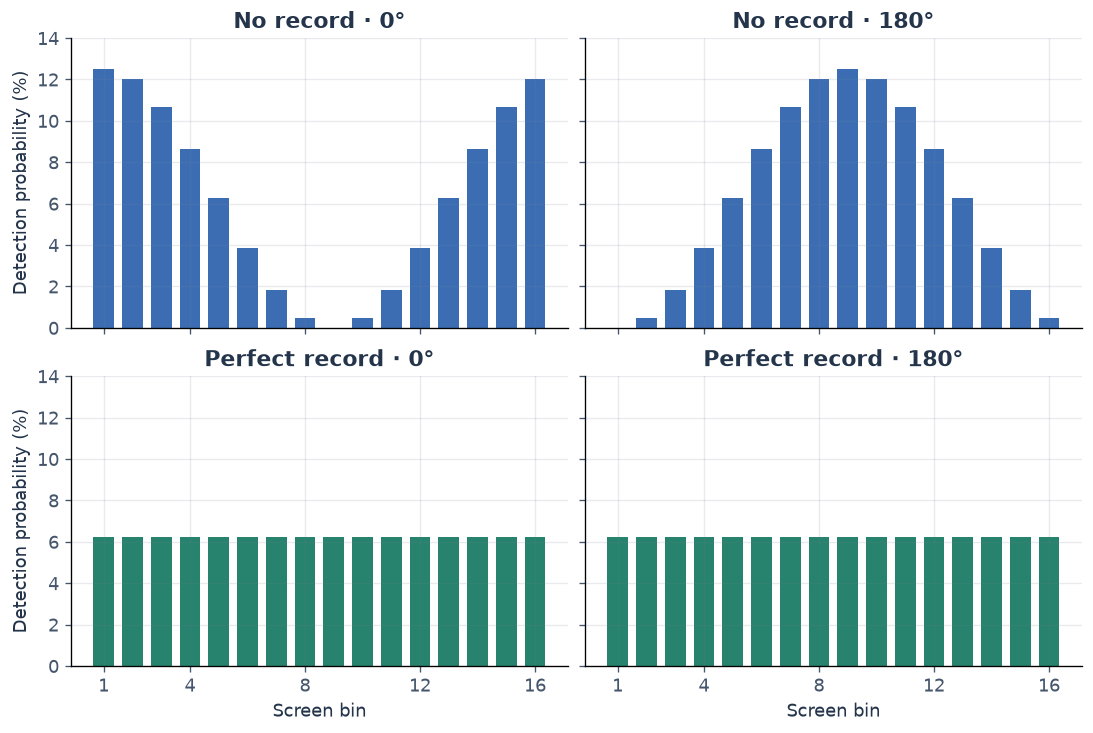

All four plots have total probability 100%.
Cancellation at bin 1 redistributes probability to other bins; it does not delete detections.


In [6]:
screen_bins = bin_index + 1
fig, axes = plt.subplots(
    2, 2, figsize=(9.0, 6.0), layout="constrained", sharex=True, sharey=True
)
cases = [(0, False), (180, False), (0, True), (180, True)]
for ax, (phase, recorded) in zip(axes.flat, cases):
    p = screen_probabilities(phase, recorded)
    ax.bar(screen_bins, 100 * p, color=GREEN if recorded else BLUE, width=0.72)
    ax.set(
        title=f"{'Perfect record' if recorded else 'No record'} · {phase}°",
        ylim=(0, 14),
    )
    ax.set_xticks([1, 4, 8, 12, 16])
for ax in axes[:, 0]:
    ax.set_ylabel("Detection probability (%)")
for ax in axes[1]:
    ax.set_xlabel("Screen bin")
plt.show()
print("All four plots have total probability 100%.")
print(
    "Cancellation at bin 1 redistributes probability to other bins; it does not "
    "delete detections."
)

## 7. Distinguish the prediction from detections

A probability distribution describes repeated identical preparations. One detection selects one bin; it does not draw the entire pattern. Sample from the no-record, `0°` distribution using an explicit random generator.

Compare 1, 100, and 10,000 detections. The observed bars fluctuate around the theoretical prediction. More detections usually improve the overall agreement, but individual bin errors need not shrink monotonically in every run.

    1 detection: observed fractions sum to 1.000000
The single detection landed in bin 4.
  100 detections: observed fractions sum to 1.000000
10,000 detections: observed fractions sum to 1.000000


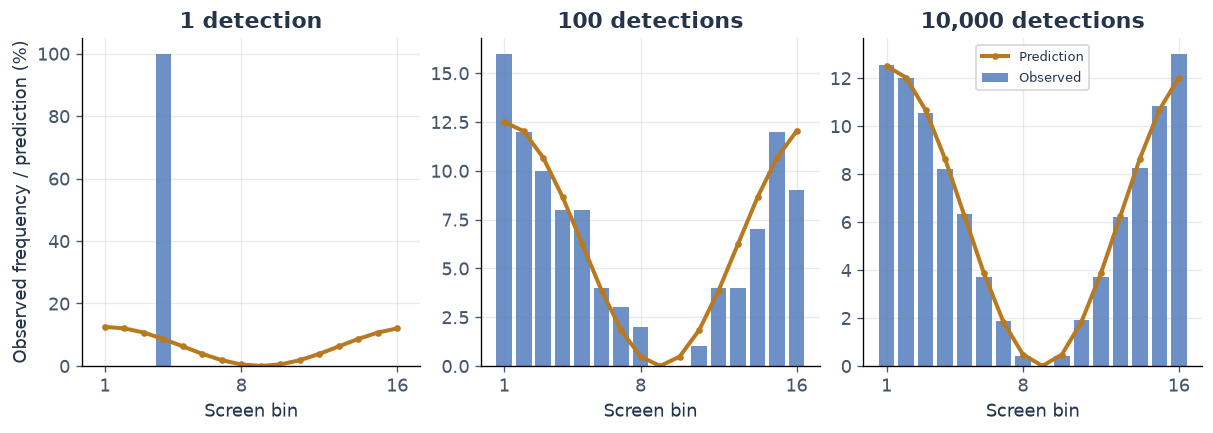

In [7]:
predicted = screen_probabilities(0)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout="constrained")
for ax, count in zip(axes, [1, 100, 10_000]):
    samples = rng.choice(BINS, size=count, p=predicted)
    counts = np.bincount(samples, minlength=BINS)
    observed = counts / count
    ax.bar(screen_bins, 100 * observed, color=BLUE, alpha=0.75, label="Observed")
    ax.plot(screen_bins, 100 * predicted, color=AMBER, marker=".", label="Prediction")
    ax.set(title=f"{count:,} detection{'s' if count != 1 else ''}", xlabel="Screen bin")
    ax.set_xticks([1, 8, 16])
    print(
        f"{count:5,d} detection{'s' if count != 1 else ''}: observed fractions sum to "
        f"{observed.sum():.6f}"
    )
    if count == 1:
        print(f"The single detection landed in bin {samples[0] + 1}.")
    assert counts.sum() == count
axes[0].set_ylabel("Observed frequency / prediction (%)")
axes[2].legend(fontsize=8)
plt.show()

**Take this with you:** first combine coherent amplitude contributions, then square their magnitude. The prediction is a normalized distribution; detections are individual samples from it.

**Try a change locally:** set the phase to `90°`, predict bin 1, then repeat the sample plot. Next set `recorded=True` and repeat. The coherent calculation should give `6.25%` in bin 1 at `90°`; the ideal recorded distribution gives `6.25%` in every bin at every phase.

References: [Feynman, quantum behaviour](https://www.feynmanlectures.caltech.edu/III_01.html) and [IBM, fundamentals of quantum information](https://quantum.cloud.ibm.com/learning/courses/basics-of-quantum-information).